In [1]:
import pandas as pd
from data_quality_checks import run_quality_checks, completeness_report,normalize_columns
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

In [2]:
# Asignar la ruta de los archivos
output_path = Path(
    r"C:\Users\oscar\OneDrive - Universidad de los Andes\Posgrado\03. Gerencia de proyectos Analytics\data"
)

df = pd.read_parquet(
    output_path / "dataset_batch_001.parquet"
)

df = df[df['departamento'] == 'ANTIOQUIA']

res = run_quality_checks(df, n_categories=4, category_by="YEAR_RADICA")
                        #export_path="reporte_calidad.xlsx")

print("\n".join(res.findings))   # the headline summary

Registros analizados: 4,988,870.
Completitud: columnas por debajo del 95% -> FECHA_APERTURA_TEXTO (78.2%).
VALOR: 100.0% diligenciado en los actos que declaran valor (TIENE_VALOR = 1); 36.3% sobre el total de registros.
Columnas de llenado condicional con baja completitud (confirmar con el dueño si es esperado): FOLIOS_DERIVADOS (0.6%); ESTADO_FOLIO (26.5%).
Duplicados: MATRICULA + NUM_ANOTACION repetidos: 1,306 filas (0.03%); Mismo folio, fecha, acto, documento y valor: 86,208 filas (1.73%).
Reglas de validez: 7 de 27 reglas con hallazgos; 3 críticas. Críticas: FECHA_RADICA_INVALIDA (1,146,383); VALOR_NO_POSITIVO (785,558); FECHA_APERTURA_INVALIDA (7).
Valores atípicos (IQR sobre log10): 17,771 bajos (< 144,563) y 766 altos (> 10,728,955,962) COP.
Categorías de valor -> 1-Bajo: 255,782 transacciones; 2-Medio bajo: 257,833 transacciones; 3-Medio alto: 256,143 transacciones; 4-Alto: 257,621 transacciones; Sin valor: 3,961,491 transacciones.


In [3]:
df.head()

,pk,matricula,fecha_radica_texto,fecha_apertura_texto,year_radica,orip,divipola,departamento,municipio,tipo_predio_zona,...,count_de,predios_nuevos,tiene_valor,tiene_mas_de_un_valor,:id,:created_at,:updated_at,valor,estado_folio,folios_derivados
0,05001-001-000013-00014-00313-2018,001-13,2018-02-05 00:00:00,1973-01-11 00:00:00,2018,1,5001,ANTIOQUIA,MEDELLÍN,URBANO,...,1,0,0,0,row-4amv.bwhd-4u7z,2025-04-04T15:08:38.467Z,2025-04-04T15:08:38.467Z,NaN,NaN,NaN
1,05001-001-000014-00015-00313-2018,001-14,2018-02-05 00:00:00,1973-01-11 00:00:00,2018,1,5001,ANTIOQUIA,MEDELLÍN,URBANO,...,1,0,0,0,row-u57d~kjwq~xs72,2025-04-04T15:08:38.467Z,2025-04-04T15:08:38.467Z,NaN,NaN,NaN
2,05001-001-000023-00007-00109-2020,001-23,2020-12-02 00:00:00,1973-01-10 00:00:00,2020,1,5001,ANTIOQUIA,MEDELLÍN,URBANO,...,1,0,0,0,row-2kwx_xgtn_nef2,2025-04-04T15:08:38.467Z,2025-04-04T15:08:38.467Z,NaN,NaN,NaN
3,05001-001-000065-00013-00317-2015,001-65,2015-12-16 00:00:00,1973-01-10 00:00:00,2015,1,5001,ANTIOQUIA,MEDELLÍN,URBANO,...,1,0,0,0,row-uden_n4dc-6sve,2025-04-04T15:08:38.467Z,2025-04-04T15:08:38.467Z,NaN,NaN,NaN
4,05001-001-000067-00014-00109-2016,001-67,2016-03-29 00:00:00,1973-01-11 00:00:00,2016,1,5001,ANTIOQUIA,MEDELLÍN,URBANO,...,1,0,0,0,row-8ww5-9shf-qwem,2025-04-04T15:08:38.467Z,2025-04-04T15:08:38.467Z,NaN,NaN,NaN


# Data Quality Report: Property Transactions (Antioquia)

This notebook runs the quality checks in `data_quality_checks.py` on a DataFrame that is **already loaded**
and explains how to read each result. The last section has the charts.

**Quick map: what you want → where it is**

| What you want | Where it is |
|---|---|
| Completeness % per column | `res.tables["completitud"]` |
| Duplicate summary | `res.tables["duplicados"]` |
| Which rules failed and how many rows | `res.tables["reglas"]` |
| Outlier thresholds | `res.tables["outliers_metodos"]` |
| Rows to review as outliers | `res.tables["outliers_filas"]` |
| Value categories (volume and value) | `res.tables["categorias"]` |
| Your data plus the new columns | `res.df` |

In [39]:

tabla = res.tables["categorias"].copy()

# Format integer columns
columnas_enteras = [
    "transacciones",
    "valor_minimo",
    "valor_maximo",
    "valor_total"
]

for col in columnas_enteras:
    tabla[col] = tabla[col].apply(
        lambda x: f"{x:,.0f}" if pd.notna(x) else ""
    )

# Format monetary averages and median
columnas_monetarias = [
    "valor_mediana",
    "valor_promedio"
]

for col in columnas_monetarias:
    tabla[col] = tabla[col].apply(
        lambda x: f"{x:,.2f}" if pd.notna(x) else ""
    )

# Format percentages
columnas_porcentaje = [
    "pct_transacciones",
    "pct_valor_total"
]

for col in columnas_porcentaje:
    tabla[col] = tabla[col].apply(
        lambda x: f"{x:.2f}%" if pd.notna(x) else ""
    )

display(tabla)

,categoria,transacciones,valor_minimo,valor_mediana,valor_promedio,valor_maximo,valor_total,pct_transacciones,pct_valor_total
0,1-Bajo,"255,782",0,"3,200,000.00","4,307,740.35","14,993,601","1,101,842,443,102",24.90%,0.02%
1,2-Medio bajo,"257,833","4,000,000","20,000,000.00","25,912,138.56","69,999,888","6,681,004,420,336",25.10%,0.15%
2,3-Medio alto,"256,143","12,002,000","100,000,000.00","101,014,434.99","229,974,000","25,874,140,421,963",24.93%,0.57%
3,4-Alto,"257,621","41,265,000","318,568,000.00","17,359,082,092.20","3,789,999,940,000,000","4,472,064,087,674,202",25.08%,99.25%
4,Sin valor,"3,961,491",,,,,,79.41%,


In [5]:
EXCLUDE_EXTREMES = False

d = res.df.copy()
d["VALOR"] = pd.to_numeric(d["VALOR"], errors="coerce")

# Records that can be used for value charts: positive value, optionally without extreme outliers
d_val = d[d["VALOR"] > 0]
if EXCLUDE_EXTREMES:
     d_val = d_val[~d_val["VALOR_OUTLIER_EXTREMO"]]

def cop_short(x, _=None):
    """Values expressed in millions of Colombian pesos."""
    return f"${x / 1_000_000:,.1f} millones"

print(f"Registros: {len(d):,} | con valores: {len(d_val):,}")

Registros: 4,988,870 | con valores: 1,027,379


In [60]:
# Minimum and maximum values
print("Minimum value:", d["VALOR"].min())
print("Maximum value:", d["VALOR"].max())

# Express values in millions of COP
print("Minimum (millions COP):", d["VALOR"].min() / 1_000_000)
print("Maximum (millions COP):", d["VALOR"].max() / 1_000_000)

Minimum value: 0.0
Maximum value: 3789999940000000.0
Minimum (millions COP): 0.0
Maximum (millions COP): 3789999940.0


In [66]:
d_val.columns

Index(['PK', 'MATRICULA', 'FECHA_RADICA_TEXTO', 'FECHA_APERTURA_TEXTO',
       'YEAR_RADICA', 'ORIP', 'DIVIPOLA', 'DEPARTAMENTO', 'MUNICIPIO',
       'TIPO_PREDIO_ZONA', 'CATEGORIA_RURALIDAD', 'NUM_ANOTACION',
       'DINAMICA_INMOBILIARIA', 'COD_NATUJUR', 'NOMBRE_NATUJUR',
       'DOCUMENTO_JUSTIFICATIVO', 'COUNT_A', 'COUNT_DE', 'PREDIOS_NUEVOS',
       'TIENE_VALOR', 'TIENE_MAS_DE_UN_VALOR', ':ID', ':CREATED_AT',
       ':UPDATED_AT', 'VALOR', 'ESTADO_FOLIO', 'FOLIOS_DERIVADOS',
       'VALOR_OUT_IQR_LOG', 'VALOR_OUT_IQR_RAW', 'VALOR_OUT_MAD',
       'VALOR_N_METODOS', 'VALOR_OUTLIER', 'VALOR_OUTLIER_EXTREMO',
       'VALOR_FUERA_RANGO_PLAUSIBLE', 'VALOR_CATEGORIA', 'VALOR_MILLONES'],
      dtype='str')

In [63]:
resumen_tipo = (
    d.groupby("NOMBRE_NATUJUR")["VALOR"]
    .sum()
    .reset_index(name="VALOR_TOTAL")
    .sort_values("VALOR_TOTAL", ascending=False)
)

display(resumen_tipo)

,NOMBRE_NATUJUR,VALOR_TOTAL
110,CANCELACIÓN POR VOLUNTAD DE LAS PARTES,4.310300e+15
131,COMPRAVENTA,9.807889e+13
442,TRANSFERENCIA DE DOMINIO A TÍTULO DE BENEFICIO...,3.265573e+13
451,TRANSFERENCIA DE DOMINO POR ADICIÓN A FIDUCIA ...,1.600053e+13
138,COMPRAVENTA PARCIAL,1.056748e+13
...,...,...
209,DEMANDA EN PROCESO DE DIVORCIO,0.000000e+00
208,DEMANDA EN PROCESO DE DESLINDE Y AMOJONAMIENTO,0.000000e+00
207,DEMANDA EN PROCESO DE DECLARATORIA DE UNIÓN MA...,0.000000e+00
206,DEMANDA EN ACUERDO DE REESTRUCTURACIÓN,0.000000e+00


In [67]:
d_val.VALOR.max()

3789999940000000.0

## Chart 1. Records per year

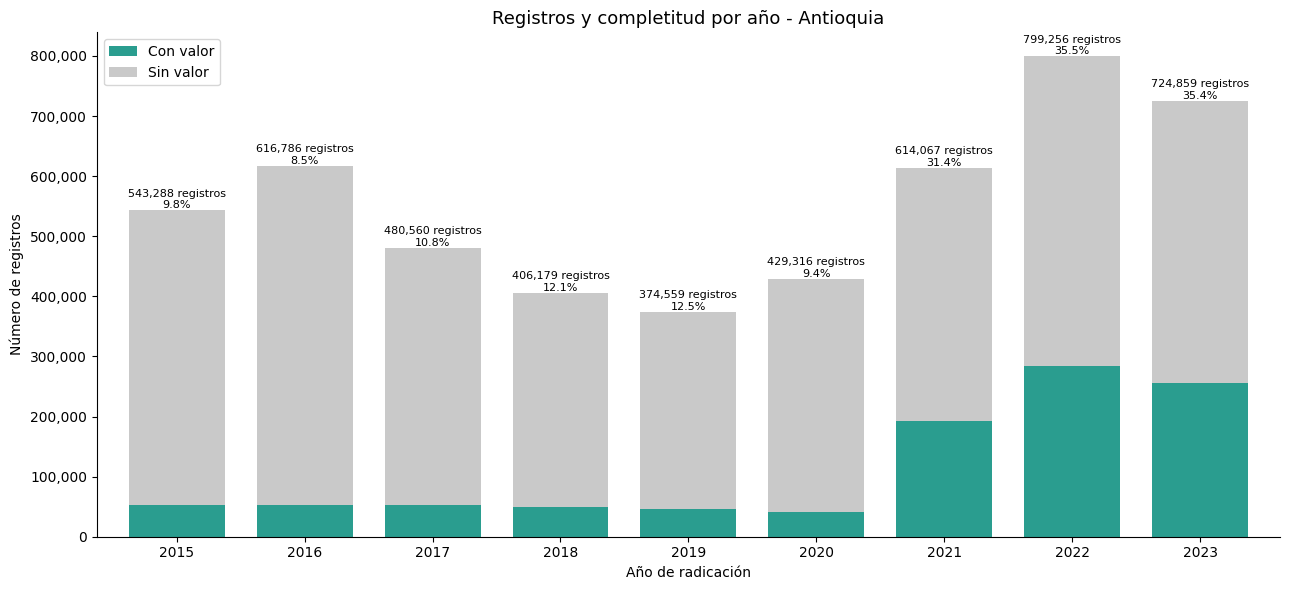

In [33]:
# 1. Clasificar registros según disponibilidad de VALOR
d = d.assign(
    Con_valor=np.where(d["VALOR"] > 0, "Con valor", "Sin valor")
)

# 2. Agrupar por año y clasificación
by_year = (
    d.groupby(["YEAR_RADICA", "Con_valor"])
    .size()
    .unstack(fill_value=0)
)

by_year = by_year.reindex(
    columns=["Con valor", "Sin valor"],
    fill_value=0
)

# 3. Calcular total y porcentaje de completitud
by_year["Total"] = by_year["Con valor"] + by_year["Sin valor"]

by_year["Completitud"] = (
    by_year["Con valor"] / by_year["Total"] * 100
)

# 4. Crear gráfico de barras apiladas
ax = by_year[["Con valor", "Sin valor"]].plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6),
    color=["#2a9d8f", "#c9c9c9"],
    width=0.75
)

# 5. Agregar cantidad total y porcentaje de completitud
for i in range(len(by_year)):

    total = by_year["Total"].iloc[i]
    completitud = by_year["Completitud"].iloc[i]

    ax.text(
        i,
        total,
        f"{total:,.0f} registros\n{completitud:.1f}%",
        ha="center",
        va="bottom",
        fontsize=8
    )

# 6. Configuración del gráfico
ax.set_title("Registros y completitud por año - Antioquia", fontsize=13)
ax.set_xlabel("Año de radicación")
ax.set_ylabel("Número de registros")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x:,.0f}")
)

ax.legend(title="")
ax.spines[["top", "right"]].set_visible(False)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

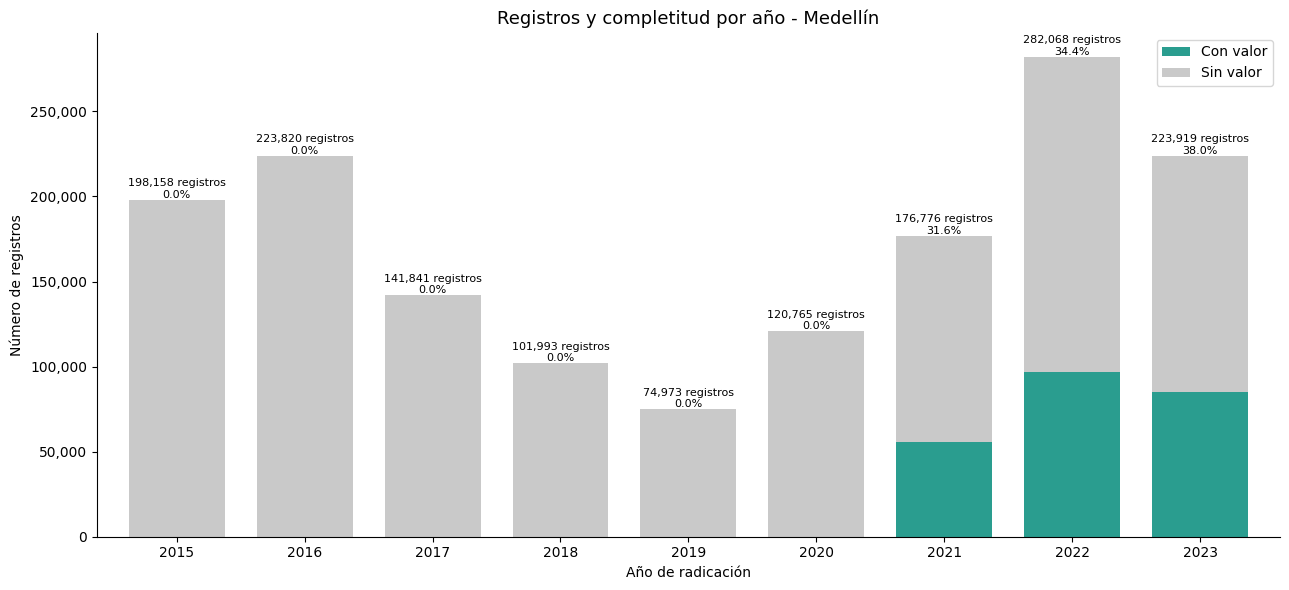

In [76]:
# 1. Clasificar registros según disponibilidad de VALOR
d = d.assign(
    Con_valor=np.where(d["VALOR"] > 0, "Con valor", "Sin valor")
)

# 2. Agrupar por año y clasificación
by_year = (
    d.groupby(["YEAR_RADICA", "Con_valor"])
    .size()
    .unstack(fill_value=0)
)

by_year = by_year.reindex(
    columns=["Con valor", "Sin valor"],
    fill_value=0
)

# 3. Calcular total y porcentaje de completitud
by_year["Total"] = by_year["Con valor"] + by_year["Sin valor"]

by_year["Completitud"] = (
    by_year["Con valor"] / by_year["Total"] * 100
)

# 4. Crear gráfico de barras apiladas
ax = by_year[["Con valor", "Sin valor"]].plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6),
    color=["#2a9d8f", "#c9c9c9"],
    width=0.75
)

# 5. Agregar cantidad total y porcentaje de completitud
for i in range(len(by_year)):

    total = by_year["Total"].iloc[i]
    completitud = by_year["Completitud"].iloc[i]

    ax.text(
        i,
        total,
        f"{total:,.0f} registros\n{completitud:.1f}%",
        ha="center",
        va="bottom",
        fontsize=8
    )

# 6. Configuración del gráfico
ax.set_title("Registros y completitud por año - Medellín", fontsize=13)
ax.set_xlabel("Año de radicación")
ax.set_ylabel("Número de registros")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x:,.0f}")
)

ax.legend(title="")
ax.spines[["top", "right"]].set_visible(False)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Chart 2. Suma de valores por año

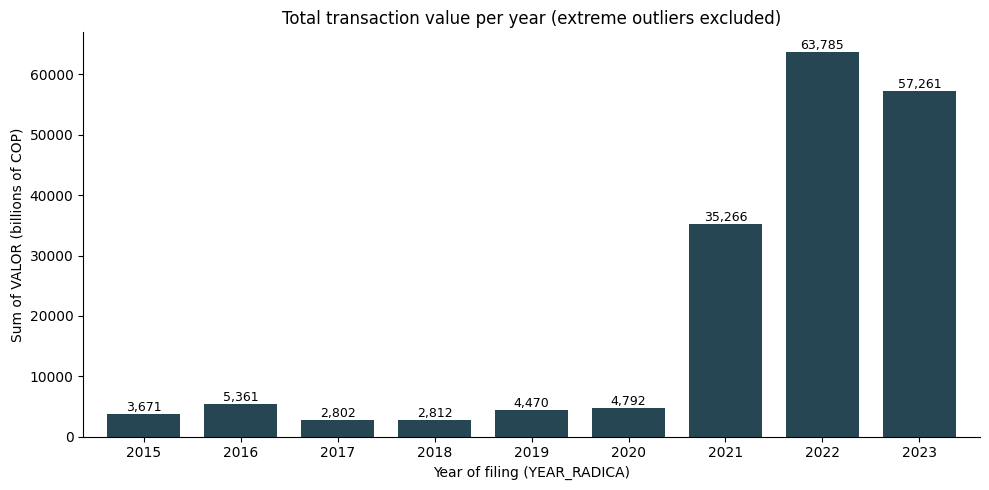

In [9]:
sum_year = d_val.groupby("YEAR_RADICA")["VALOR"].sum() / 1e9      # miles de millones de COP

ax = sum_year.plot(kind="bar", figsize=(10, 5), color="#264653", width=0.75)
for i, v in enumerate(sum_year):
    ax.text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
ax.set_title("Total transaction value per year" + (" (extreme outliers excluded)" if EXCLUDE_EXTREMES else ""))
ax.set_xlabel("Year of filing (YEAR_RADICA)")
ax.set_ylabel("Sum of VALOR (billions of COP)")
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Chart 3. Histograma de `VALOR`

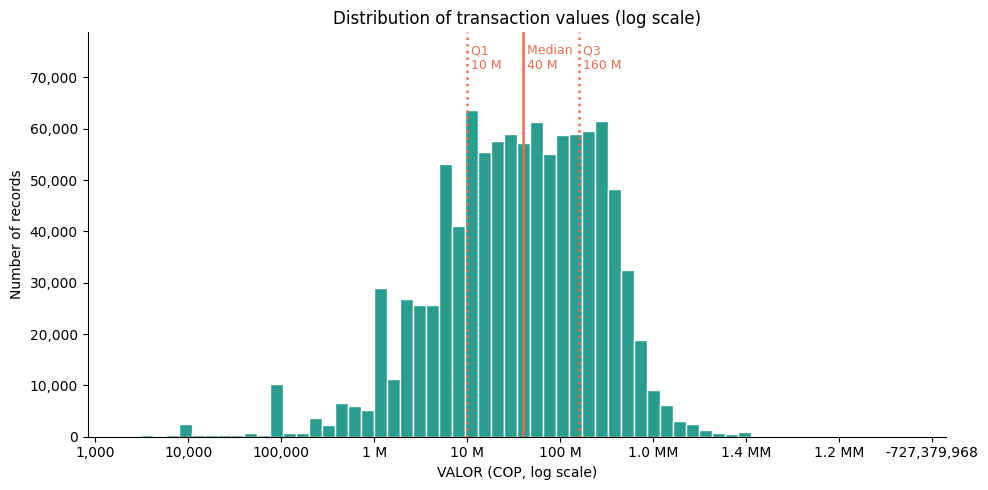

In [10]:
log_v = np.log10(d_val["VALOR"])
q1, med, q3 = log_v.quantile([0.25, 0.5, 0.75])

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(log_v, bins=60, color="#2a9d8f", edgecolor="white")
ax.set_ylim(top=ax.get_ylim()[1] * 1.18)          # headroom so the labels do not overlap the bars
for q, name, style in [(q1, "Q1", ":"), (med, "Median", "-"), (q3, "Q3", ":")]:
    ax.axvline(q, color="#e76f51", linestyle=style, linewidth=1.8)
    ax.text(q, ax.get_ylim()[1] * 0.97, f" {name}\n {cop_short(10**q)}", color="#e76f51", va="top", fontsize=9)

lo, hi = int(np.floor(log_v.min())), int(np.ceil(log_v.max()))
ticks = np.arange(lo, hi + 1)
ax.set_xticks(ticks)
ax.set_xticklabels([cop_short(10**t) for t in ticks])
ax.set_title("Distribution of transaction values (log scale)")
ax.set_xlabel("VALOR (COP, log scale)")
ax.set_ylabel("Number of records")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

##  Histogram on the original scale (central 98% of values)

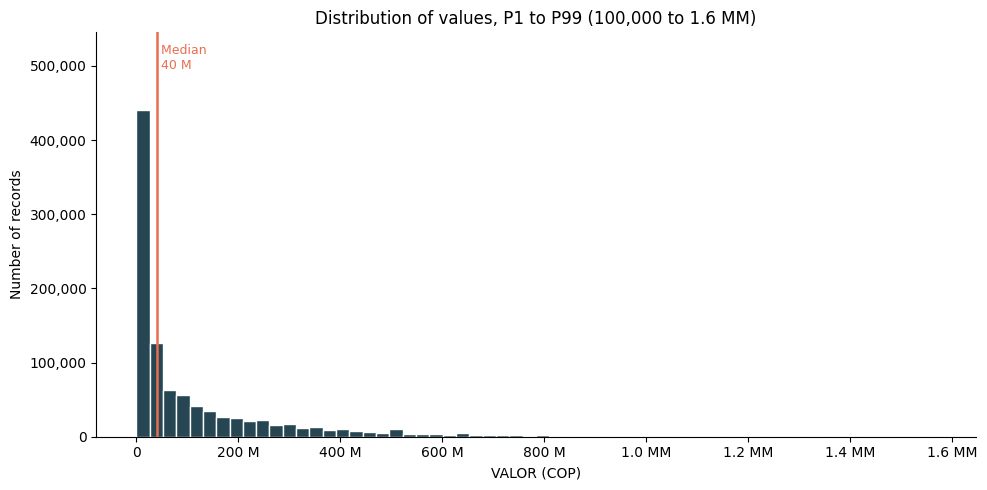

In [11]:
p1, p99 = d_val["VALOR"].quantile([0.01, 0.99])
trimmed = d_val.loc[d_val["VALOR"].between(p1, p99), "VALOR"]

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(trimmed, bins=60, color="#264653", edgecolor="white")
ax.set_ylim(top=ax.get_ylim()[1] * 1.18)
ax.axvline(trimmed.median(), color="#e76f51", linewidth=1.8)
ax.text(trimmed.median(), ax.get_ylim()[1] * 0.97, f" Median\n {cop_short(trimmed.median())}",
        color="#e76f51", va="top", fontsize=9)
ax.xaxis.set_major_formatter(FuncFormatter(cop_short))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_title(f"Distribution of values, P1 to P99 ({cop_short(p1)} to {cop_short(p99)})")
ax.set_xlabel("VALOR (COP)")
ax.set_ylabel("Number of records")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Chart 4. Box plot of `VALOR` per year

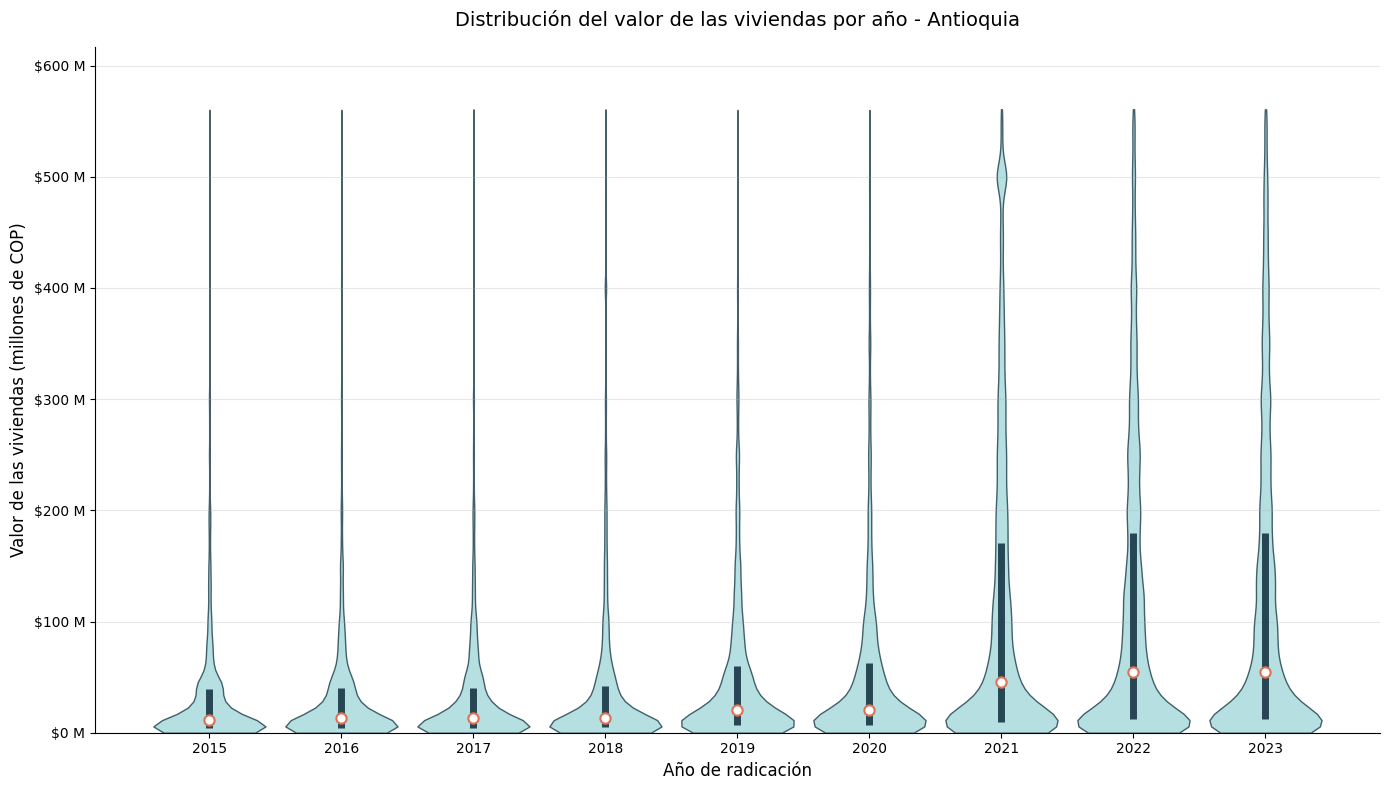

In [65]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# --------------------------------------------------
# 1. CONFIGURACIÓN
# --------------------------------------------------

CLIP_TO_PERCENTILE = 0.95  # Mostrar hasta el percentil 95

# --------------------------------------------------
# 2. PREPARAR DATOS
# --------------------------------------------------

d_val = d_val[
    d_val["VALOR"].notna() &
    (d_val["VALOR"] > 0) &
    (d_val["YEAR_RADICA"].notna())
].copy()

# Convertir a millones de COP
d_val["VALOR_MILLONES"] = d_val["VALOR"] / 1_000_000

years = sorted(d_val["YEAR_RADICA"].unique())

# Límite visual global
limite_superior = d_val["VALOR_MILLONES"].quantile(
    CLIP_TO_PERCENTILE
)

# Datos por año, limitados al percentil seleccionado
data = [
    d_val.loc[
        (d_val["YEAR_RADICA"] == y) &
        (d_val["VALOR_MILLONES"] <= limite_superior),
        "VALOR_MILLONES"
    ].values
    for y in years
]

# --------------------------------------------------
# 3. CREAR GRÁFICA
# --------------------------------------------------

positions = range(1, len(years) + 1)

fig, ax = plt.subplots(figsize=(14, 8))

parts = ax.violinplot(
    data,
    positions=positions,
    widths=0.85,
    showextrema=False
)

for body in parts["bodies"]:
    body.set(
        facecolor="#a8dadc",
        edgecolor="#264653",
        alpha=0.85
    )

# --------------------------------------------------
# 4. MEDIANA Y RANGO INTERCUARTÍLICO
# --------------------------------------------------

for pos, v in zip(positions, data):

    q1, med, q3 = np.percentile(v, [25, 50, 75])

    ax.vlines(
        pos, q1, q3,
        color="#264653",
        linewidth=5
    )

    ax.scatter(
        pos, med,
        color="white",
        edgecolor="#e76f51",
        linewidth=1.5,
        zorder=3,
        s=55
    )

# --------------------------------------------------
# 5. CONFIGURAR EJES
# --------------------------------------------------

ax.set_xticks(list(positions))
ax.set_xticklabels([str(int(y)) for y in years])

ax.set_ylim(0, limite_superior * 1.10)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x:,.0f} M")
)

# --------------------------------------------------
# 6. TÍTULOS Y PRESENTACIÓN
# --------------------------------------------------

ax.set_title(
    "Distribución del valor de las viviendas por año - Antioquia",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Año de radicación", fontsize=12)
ax.set_ylabel("Valor de las viviendas (millones de COP)", fontsize=12)

ax.grid(axis="y", alpha=0.3)

ax.spines[["top", "right"]].set_visible(False)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [72]:
print("Maximum original value (COP):", d_val["VALOR"].max())

print(
    "Maximum value (millions COP):",
    d_val["VALOR_MILLONES"].max()
)

print(
    "95th percentile (millions COP):",
    d_val["VALOR_MILLONES"].quantile(0.95)
)

print(
    "99th percentile (millions COP):",
    d_val["VALOR_MILLONES"].quantile(0.99)
)

print(
    "Transactions excluded from graph:",
    (d_val["VALOR_MILLONES"] >
     d_val["VALOR_MILLONES"].quantile(0.95)).sum()
)

Maximum original value (COP): 3789999940000000.0
Maximum value (millions COP): 3789999940.0
95th percentile (millions COP): 560.7196709999988
99th percentile (millions COP): 1568.0
Transactions excluded from graph: 51369


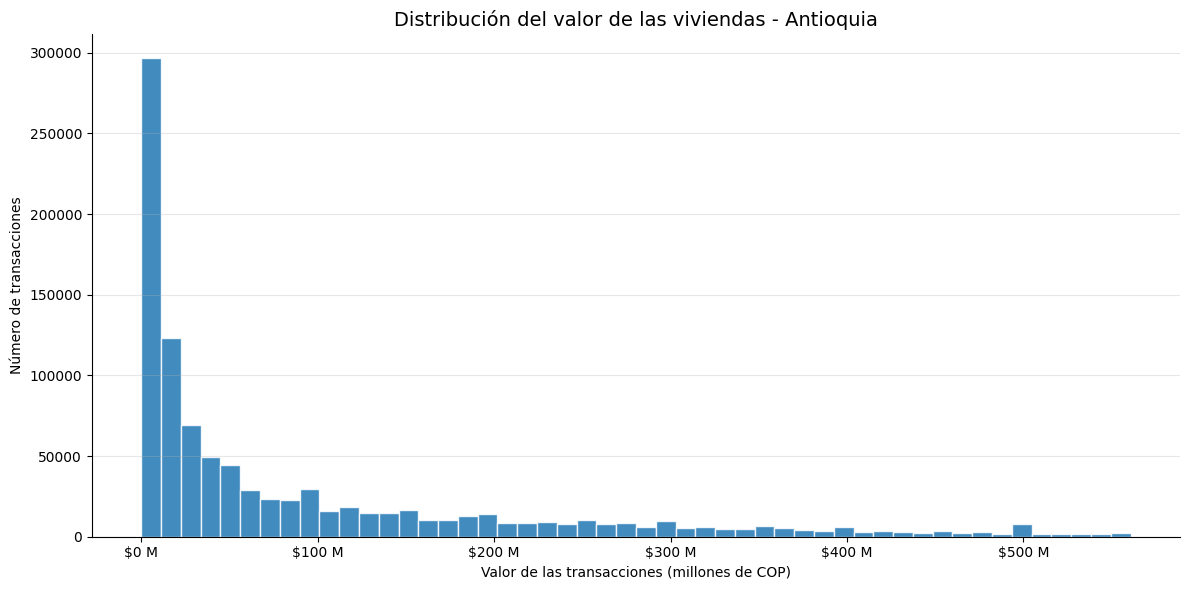

In [ ]:


# --------------------------------------------------
# 1. PREPARE DATA
# --------------------------------------------------

d_val = d_val[
    d_val["VALOR"].notna() &
    (d_val["VALOR"] > 0) &
    (d_val["YEAR_RADICA"].notna())
].copy()

d_val["VALOR_MILLONES"] = d_val["VALOR"] / 1_000_000

# Calculate 95th percentile
limite_superior = d_val["VALOR_MILLONES"].quantile(0.95)

# Filter only for visualization
datos = d_val.loc[
    d_val["VALOR_MILLONES"] <= limite_superior,
    "VALOR_MILLONES"
]

# --------------------------------------------------
# 2. CREATE HISTOGRAM
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    datos,
    bins=50,
    edgecolor="white",
    alpha=0.85
)

# --------------------------------------------------
# 3. CONFIGURE AXES
# --------------------------------------------------

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x:,.0f} M")
)

ax.set_title(
    "Distribución del valor de las viviendas - Antioquia",
    fontsize=14
)

ax.set_xlabel("Valor de las transacciones (millones de COP)")
ax.set_ylabel("Número de transacciones")

ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()